### STUDENT DEPRESSION

In [77]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

In [78]:
path_file = r'Student_Depression_Dataset.csv'
df = pd.read_csv(path_file)
df.head(10)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
5,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No
6,Female,21,Lower Middle class,Single,Unmarried,Family,9,3.50,Yes,Normal,1648,Dhaka,No
7,Female,19,Middle class,Single,Unmarried,Family,2,2.71,Yes,Abnormal,16782,Rajshahi,Yes
8,Female,21,Middle class,Single,Unmarried,Family,3,3.10,Yes,Abnormal,13386,Dhaka,Yes
9,Female,22,Middle class,In a Relationship,Married,Family,4,3.34,Yes,Normal,18131,Mymensingh,No


In [79]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [80]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


Analisi missing values

In [82]:
df.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Analisi duplicati

In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

# Data quality checks
print("Missing values per column:")
print(df.isna().sum())

print("\nUnique values per categorical column:")
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\nNumeric variables: potential impossible values")
print(df[["Age", "Current_semester", "CGPA", "Cost_without_study"]].agg(["min", "max"]))

# Coerenza logica: relazione e stato civile
print("\nRelationship status vs marital status:")
print(pd.crosstab(df["Relationship_status"], df["Marital_status"]))

Missing values per column:
Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Unique values per categorical column:

Gender:
Gender
Female    2462
Male      2002
Name: count, dtype: int64

Family_background:
Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

Relationship_status:
Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

Marital_status:
Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

Living_style:
Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

Health_condition:
Health_conditi

In [85]:
rare_categories = []

for col in categorical_columns:
    freq = df[col].value_counts(normalize=True)
    rare = freq[freq < 0.01]
    for category, proportion in rare.items():
        rare_categories.append({
            "Variable": col,
            "Category": category,
            "Count": int((df[col] == category).sum()),
            "Proportion": round(proportion * 100, 2)
        })

rare_categories = pd.DataFrame(rare_categories)
print(rare_categories)

Empty DataFrame
Columns: []
Index: []


### EXPLORATORY DATA ANALYSIS

In [86]:
# Dataset overview
total_students = len(df)

print(f"Total students: {total_students:,}")
print(f"Average age: {df['Age'].mean():.1f}")
print(f"Age range: {df['Age'].min()}–{df['Age'].max()}")
print(f"Number of semesters: {df['Current_semester'].nunique()}")

Total students: 4,464
Average age: 22.6
Age range: 17–28
Number of semesters: 14


In [87]:
# descrittivo delle variabili numeriche
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


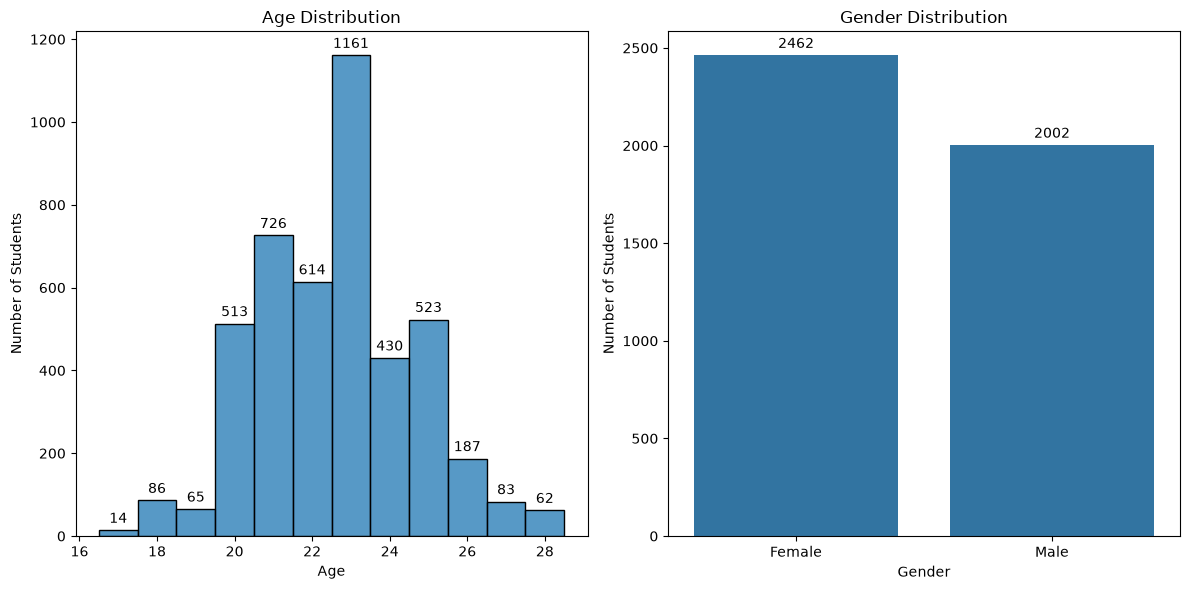

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=12,
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Students")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Gender Distribution
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1]
)
axes[1].set_title("Gender Distribution")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Students")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

Il campione presenta un'età compresa tra i 16 e i 28 anni, con la maggior parte della popolazione concentrata nella fascia 20-24. Risulta abbastanza bilanciato nella distribuzione del genere.

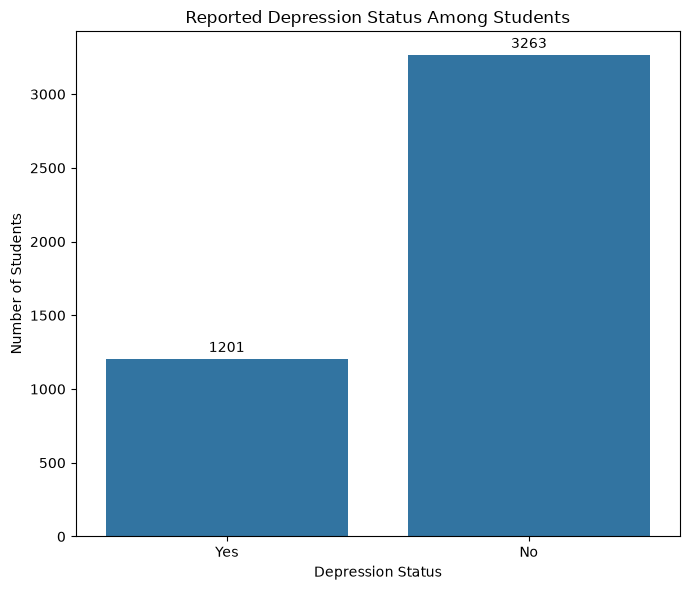

In [89]:
depression_counts = df["Depression"].value_counts()

depression_pct = (
    df["Depression"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

depression_summary = pd.DataFrame({
    "Count": depression_counts,
    "Percentage": depression_pct
})

plt.figure(figsize=(7, 6))

ax = sns.countplot(
    data=df,
    x="Depression"
)

# Add count labels above each bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_title("Reported Depression Status Among Students")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

Circa il 27% degli studenti si dichiara depresso.

In [90]:
# funzione per visualizzare come si distribuiscono i predittori in base alla var. target  
def plot_depression_comparison(column, title, order=None):
    colors = {"No": "tab:blue", "Yes": "tab:orange"}

    # Define one consistent category order for both charts
    if order is None:
        order = df[column].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Count
    sns.countplot(
        data=df,
        x=column,
        hue="Depression",
        order=order,
        hue_order=["No", "Yes"],
        palette=colors,
        ax=axes[0]
    )

    axes[0].set_title(f"Number of students by {title} and Depression Status")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Number of Students")
    axes[0].tick_params(axis="x", rotation=15)

    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.0f", padding=3, fontsize=8
        )

    # Percentage
    pct = pd.crosstab(
        df[column], df["Depression"], normalize="index"
    ).mul(100).reindex(index=order, columns=["No", "Yes"], fill_value=0)

    pct.plot(
        kind="bar",
        color=[colors["No"], colors["Yes"]],
        ax=axes[1]
    )

    axes[1].set_title(f"Depression rate within each {title} (%)")
    axes[1].set_xlabel(title)
    axes[1].set_ylabel("Percentage of Students")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Depression Status")

    for container in axes[1].containers:
        axes[1].bar_label(
            container, fmt="%.1f%%", padding=3, fontsize=8
        )

    plt.tight_layout()
    plt.show()

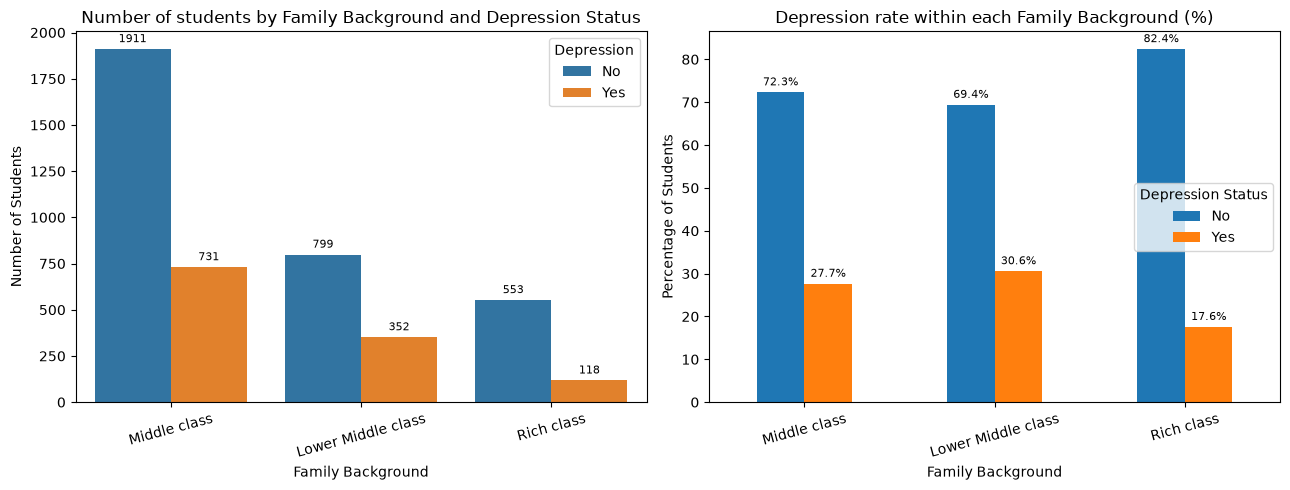

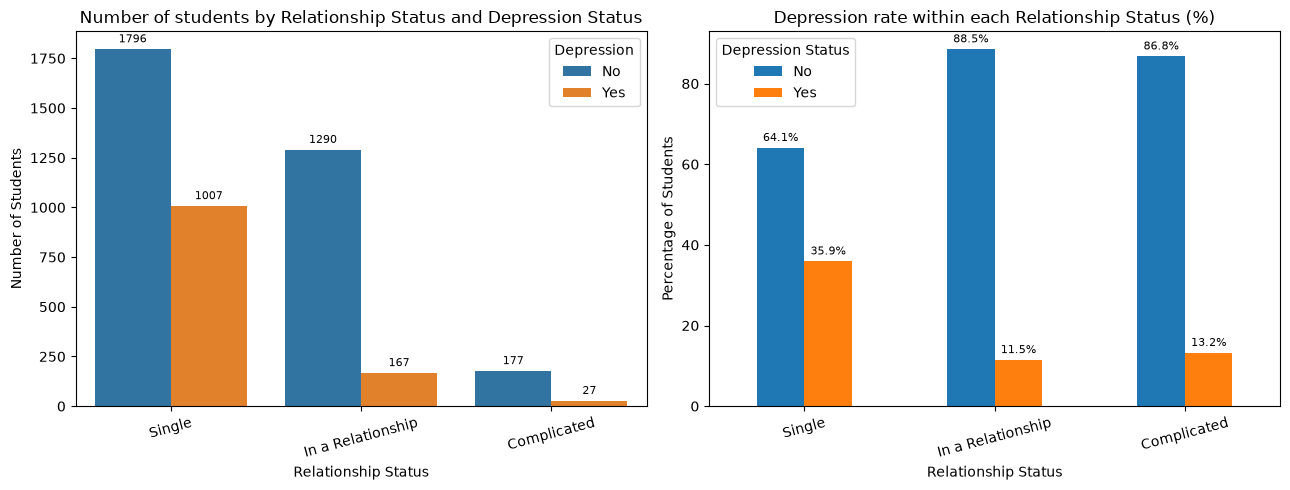

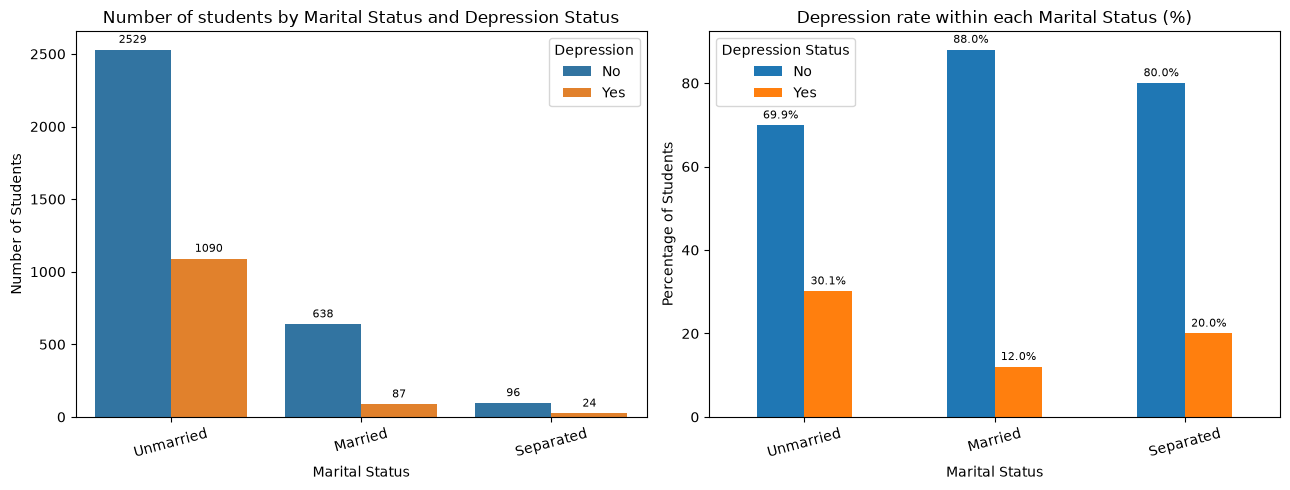

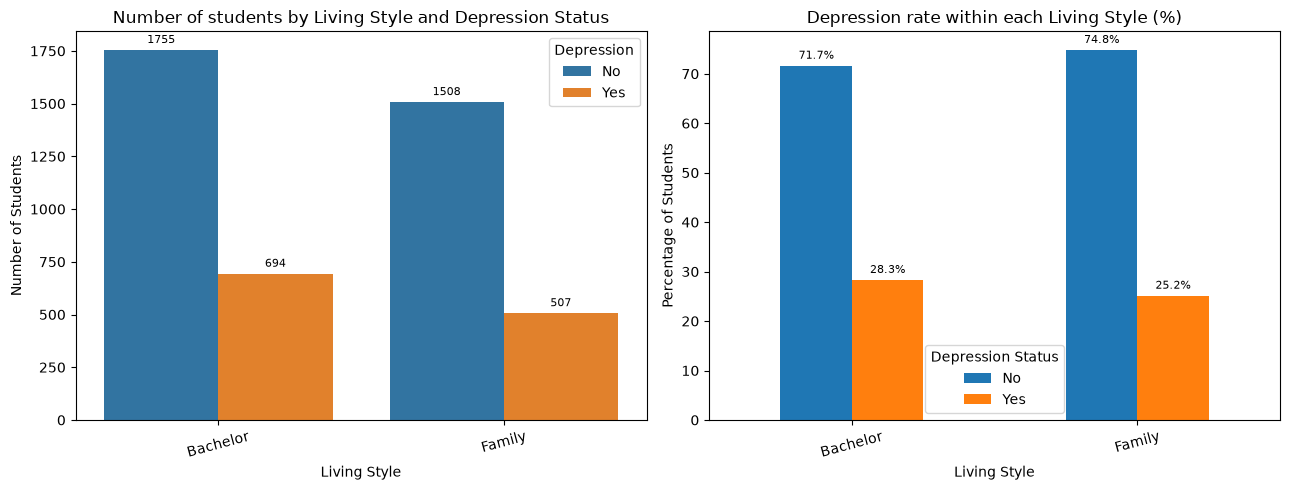

In [91]:
#1 colonna da usare
#2 titolo
plot_depression_comparison("Family_background", "Family Background")
plot_depression_comparison("Relationship_status", "Relationship Status")
plot_depression_comparison("Marital_status", "Marital Status")
plot_depression_comparison("Living_style", "Living Style")

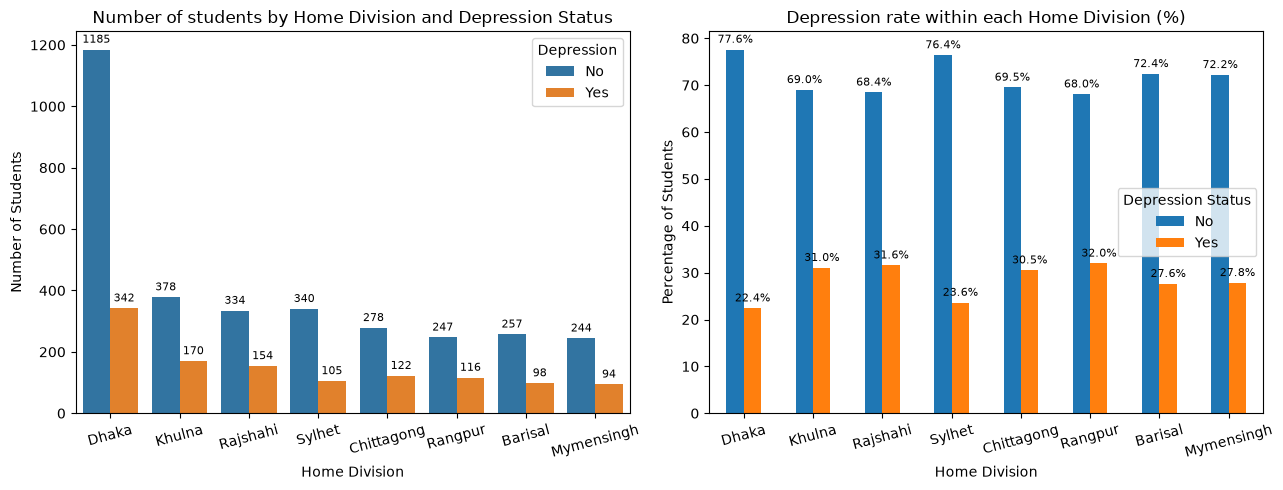

In [92]:
plot_depression_comparison("Home_division", "Home Division")


### DA ORDINARE

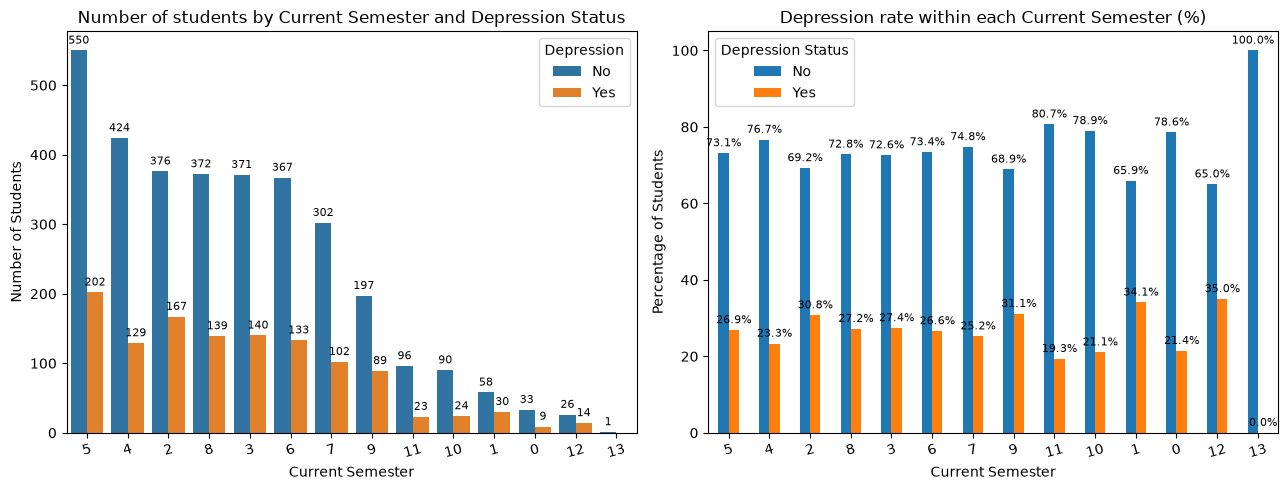

In [93]:
plot_depression_comparison("Current_semester", "Current Semester")

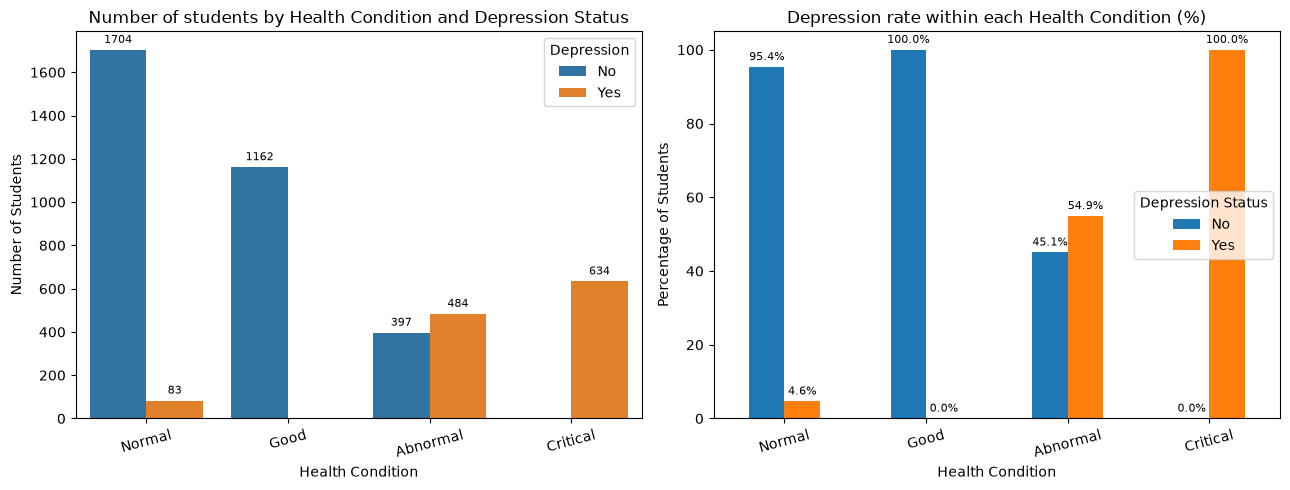

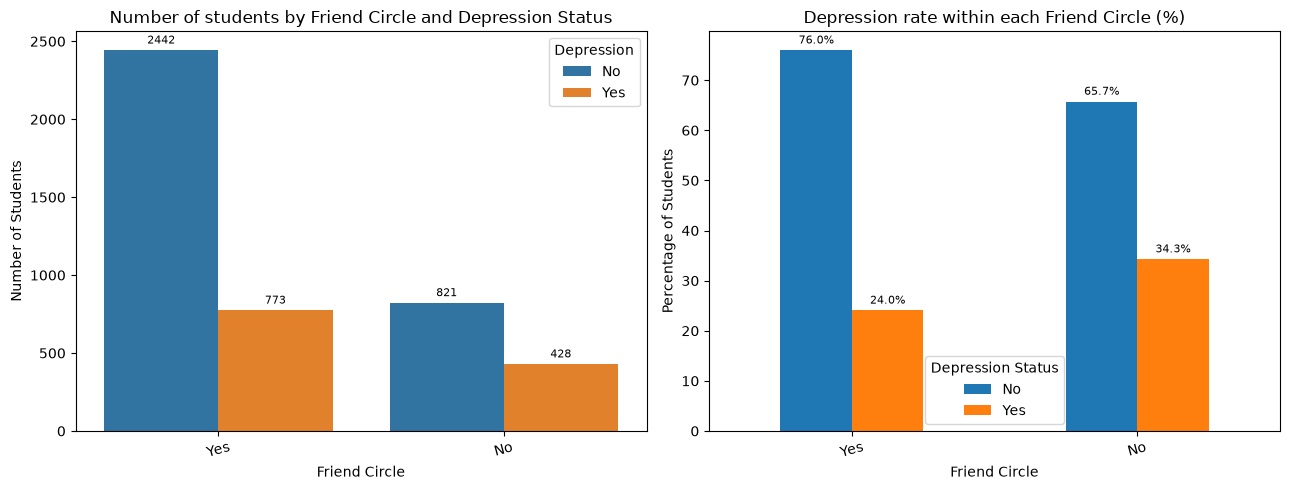

In [94]:
plot_depression_comparison("Health_condition", "Health Condition")
plot_depression_comparison("friend_circle", "Friend Circle")

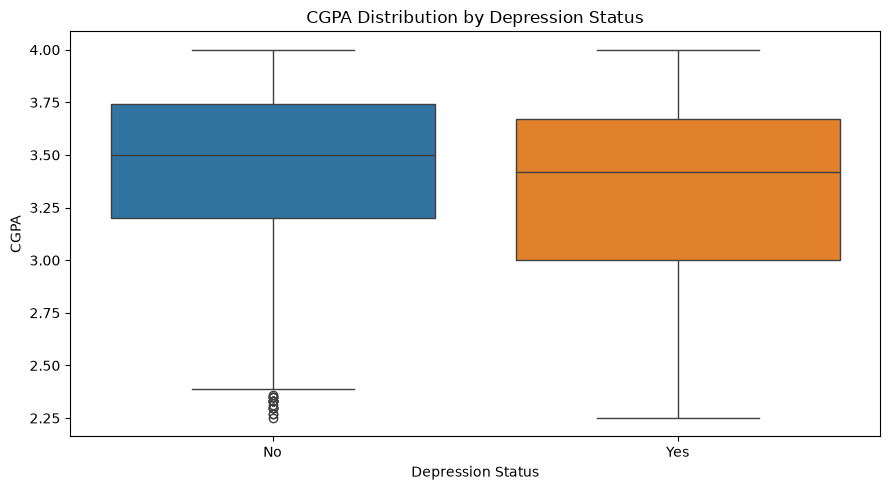

In [95]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("CGPA Distribution by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("CGPA")

plt.tight_layout()
plt.show()

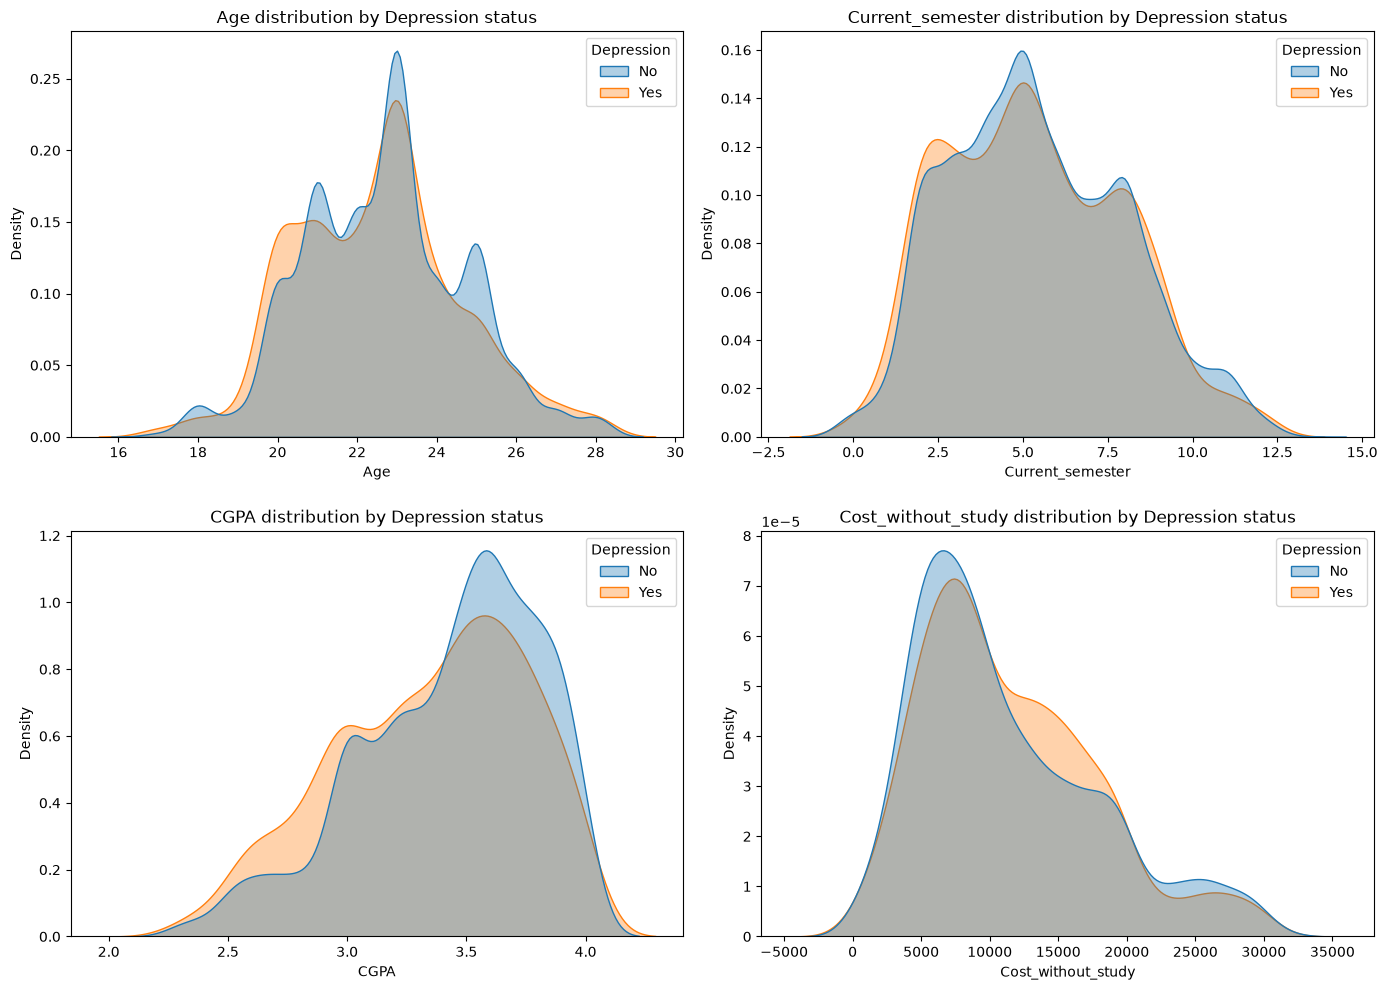

In [96]:
numeric_by_target = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.ravel(), numeric_by_target):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Depression",
        hue_order=["No", "Yes"],
        common_norm=False,
        fill=True,
        alpha=0.35,
        ax=ax
    )
    ax.set_title(f"{col} distribution by Depression status")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [97]:
numeric_summary = (
    df.groupby("Depression")[numeric_by_target]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

print(numeric_summary)

              Age                      Current_semester                       \
             mean median   std min max             mean median   std min max   
Depression                                                                     
No          22.66   23.0  2.00  17  28             5.43    5.0  2.57   0  13   
Yes         22.51   23.0  2.07  17  28             5.33    5.0  2.60   0  12   

            CGPA                         Cost_without_study                    \
            mean median   std   min  max               mean   median      std   
Depression                                                                      
No          3.44   3.50  0.38  2.25  4.0           11169.58   9300.0  6737.38   
Yes         3.35   3.42  0.40  2.25  4.0           11442.40  10000.0  6366.92   

                       
           min    max  
Depression             
No           0  32000  
Yes          0  30634  


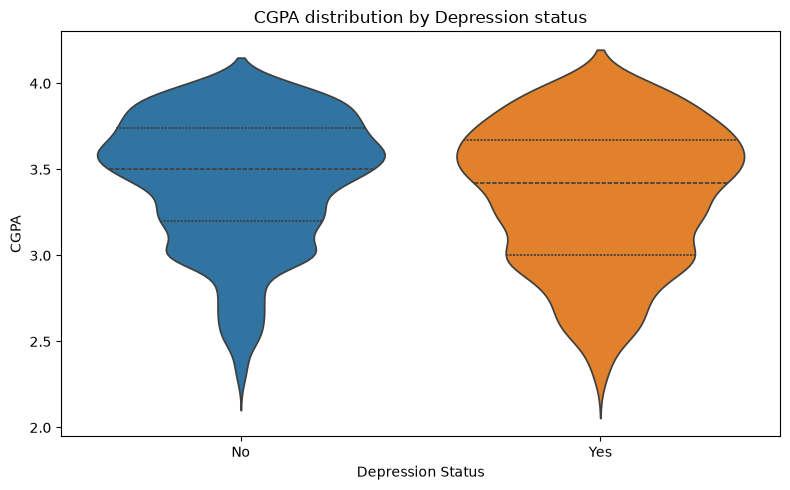

In [98]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    inner="quartile",
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False
)

plt.title("CGPA distribution by Depression status")
plt.xlabel("Depression Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()

In [99]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

summary_list = []

for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))
for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))
for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))

           Variable           Category  Depression_Rate
   Health_condition           Critical           100.00
   Health_condition           Abnormal            54.94
Relationship_status             Single            35.93
      friend_circle                 No            34.27
      Home_division            Rangpur            31.96
      Home_division           Rajshahi            31.56
      Home_division             Khulna            31.02
  Family_background Lower Middle class            30.58
      Home_division         Chittagong            30.50
     Marital_status          Unmarried            30.12
       Living_style           Bachelor            28.34
      Home_division         Mymensingh            27.81
  Family_background       Middle class            27.67
      Home_division            Barisal            27.61
             Gender               Male            27.27
             Gender             Female            26.60
       Living_style             Family          

In [100]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df["Depression"])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    r, k = contingency_table.shape

    denominator = n * min(r - 1, k - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan

    association_results.append({
        "Variable": col,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3),
    })

association_table = pd.DataFrame(association_results)

association_table["P-value"] = association_table["P-value"].map(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
)

print(association_table.to_string(index=False))

           Variable  Chi-square  Degrees of Freedom P-value  Cramer's V
             Gender        0.22                   1   0.641       0.007
  Family_background       38.33                   2 < 0.001       0.093
Relationship_status      312.06                   2 < 0.001       0.264
     Marital_status      103.82                   2 < 0.001       0.153
       Living_style        5.51                   1   0.019       0.035
   Health_condition     2952.51                   3 < 0.001       0.813
      friend_circle       47.29                   1 < 0.001       0.103
      Home_division       35.92                   7 < 0.001       0.090


In [101]:
for col in categorical_columns:
    table = pd.crosstab(df[col], df["Depression"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    expected_df = pd.DataFrame(
        expected,
        index=table.index,
        columns=table.columns
    ).round(1)

    print(f"\n### {col}")
    print("Observed counts:")
    print(table)
    print("\nExpected counts:")
    print(expected_df)


### Gender
Observed counts:
Depression    No  Yes
Gender               
Female      1807  655
Male        1456  546

Expected counts:
Depression      No    Yes
Gender                   
Female      1799.6  662.4
Male        1463.4  538.6

### Family_background
Observed counts:
Depression            No  Yes
Family_background            
Lower Middle class   799  352
Middle class        1911  731
Rich class           553  118

Expected counts:
Depression              No    Yes
Family_background                
Lower Middle class   841.3  309.7
Middle class        1931.2  710.8
Rich class           490.5  180.5

### Relationship_status
Observed counts:
Depression             No   Yes
Relationship_status            
Complicated           177    27
In a Relationship    1290   167
Single               1796  1007

Expected counts:
Depression               No    Yes
Relationship_status               
Complicated           149.1   54.9
In a Relationship    1065.0  392.0
Single               20

In [102]:
category_quality = []

for col in categorical_columns:
    counts = df[col].value_counts()
    category_quality.append({
        "Variable": col,
        "N categories": df[col].nunique(),
        "Smallest category": counts.idxmin(),
        "Smallest count": counts.min(),
        "Smallest proportion (%)": round(counts.min() / len(df) * 100, 2)
    })

print(pd.DataFrame(category_quality).to_string(index=False))

           Variable  N categories Smallest category  Smallest count  Smallest proportion (%)
             Gender             2              Male            2002                    44.85
  Family_background             3        Rich class             671                    15.03
Relationship_status             3       Complicated             204                     4.57
     Marital_status             3         Separated             120                     2.69
       Living_style             2            Family            2015                    45.14
   Health_condition             4          Critical             634                    14.20
      friend_circle             2                No            1249                    27.98
      Home_division             8        Mymensingh             338                     7.57


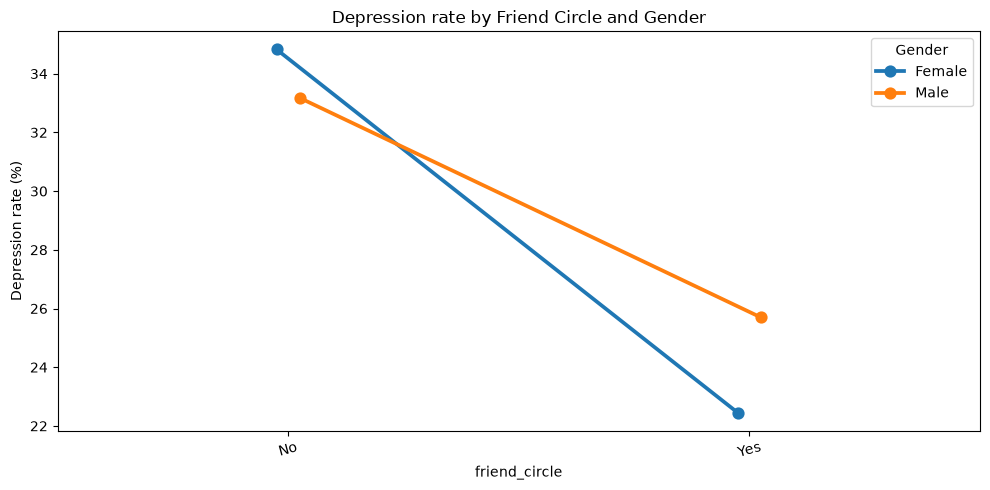

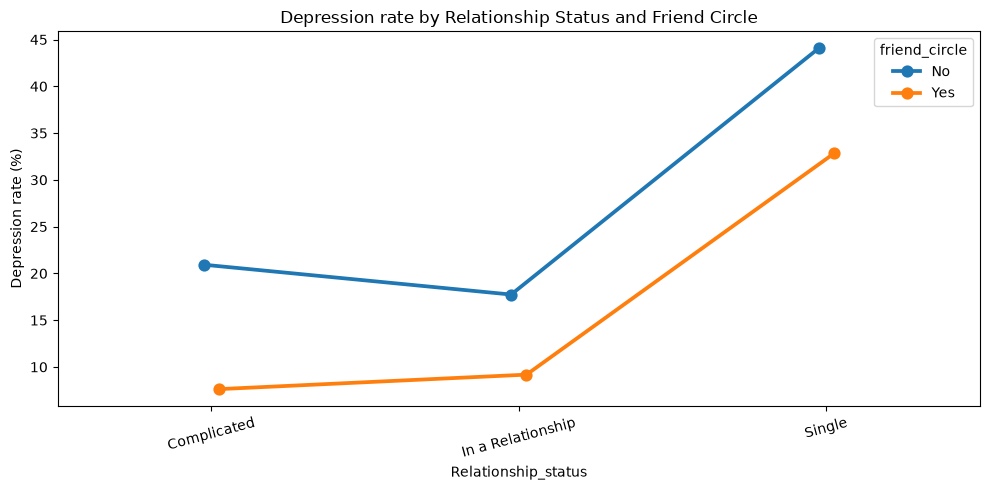

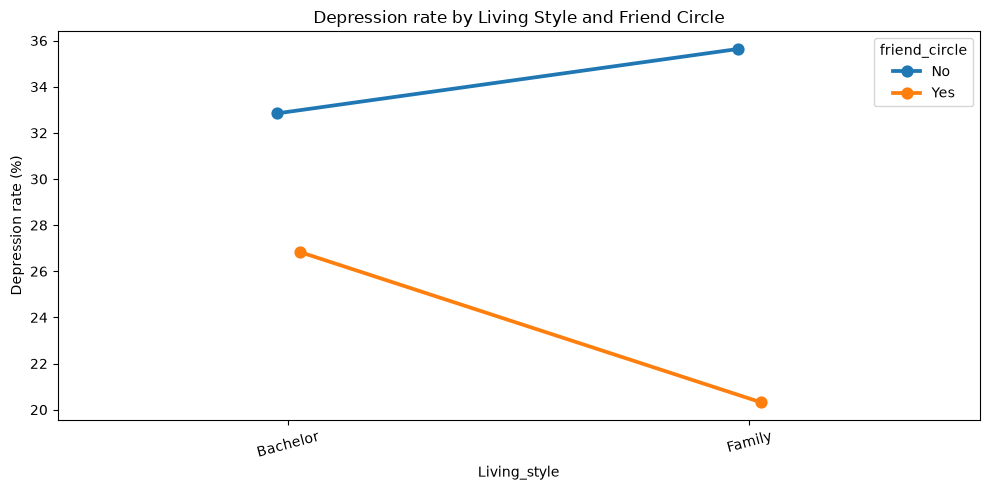

In [103]:
def plot_interaction_rate(row_var, col_var, title):
    rate = (
        df.groupby([row_var, col_var], observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )

    plt.figure(figsize=(10, 5))

    sns.pointplot(
        data=rate,
        x=row_var,
        y="Depression_Rate",
        hue=col_var,
        dodge=True,
        markers="o",
        linestyles="-"
    )

    plt.title(title)
    plt.xlabel(row_var)
    plt.ylabel("Depression rate (%)")
    plt.legend(title=col_var)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


plot_interaction_rate(
    "friend_circle",
    "Gender",
    "Depression rate by Friend Circle and Gender"
)


plot_interaction_rate(
    "Relationship_status",
    "friend_circle",
    "Depression rate by Relationship Status and Friend Circle"
)

plot_interaction_rate(
    "Living_style",
    "friend_circle",
    "Depression rate by Living Style and Friend Circle"
)

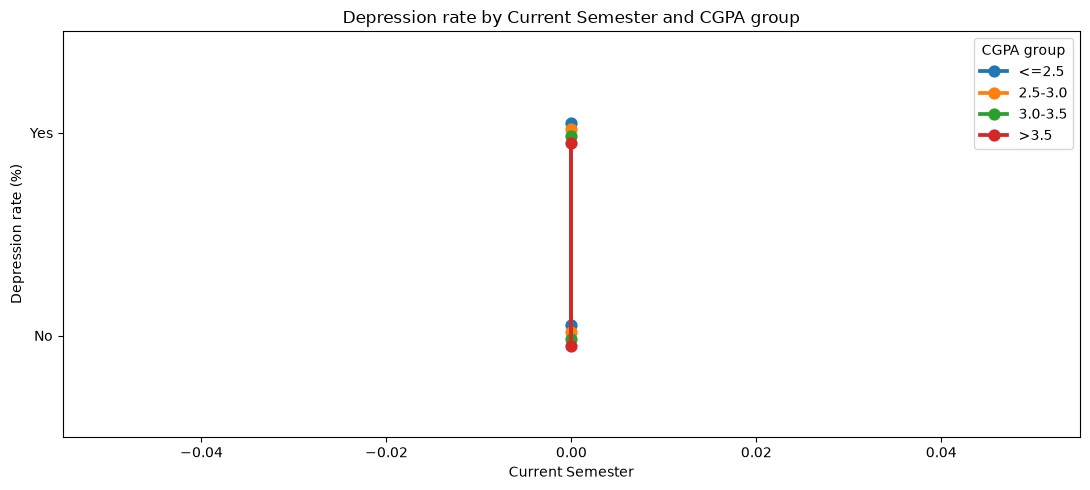

In [104]:
df["CGPA_group"] = pd.cut(
    df["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=["<=2.5", "2.5-3.0", "3.0-3.5", ">3.5"],
    include_lowest=True
)

plt.figure(figsize=(11, 5))

sns.pointplot(
    data=df,
    x="Current_semester",
    y="Depression",
    hue="CGPA_group",
    estimator=lambda x: (x == "Yes").mean() * 100,
    errorbar=("ci", 95),
    dodge=True
)

plt.title("Depression rate by Current Semester and CGPA group")
plt.xlabel("Current Semester")
plt.ylabel("Depression rate (%)")
plt.legend(title="CGPA group")
plt.tight_layout()
plt.show()

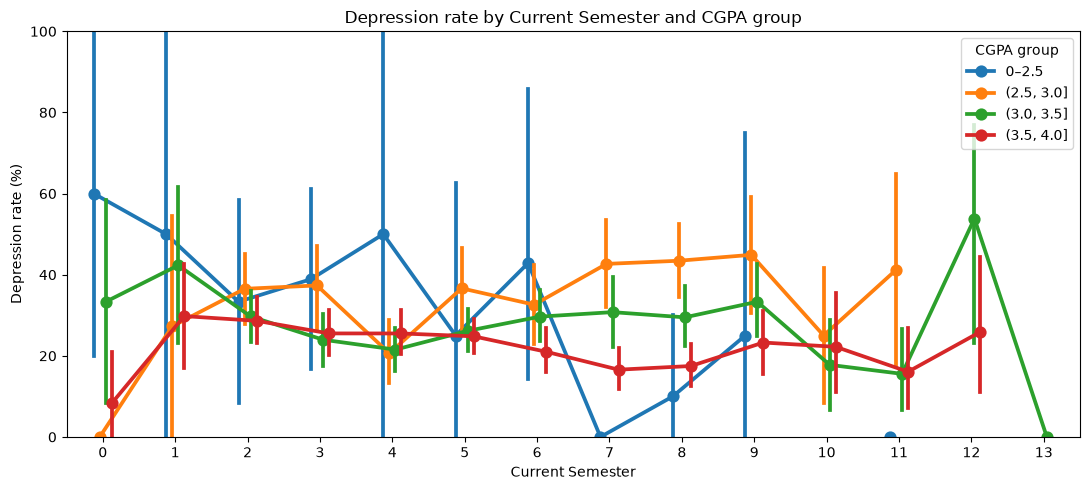

In [105]:
d = df.copy()

# Yes → 1; No → 0; eventuali valori mancanti restano mancanti
d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

# Fasce di CGPA
labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True,
    right=True
)

# Mantieni solo i record completi per le variabili utilizzate
plot_df = d.dropna(
    subset=["Current_semester", "CGPA_group", "Depression_bin"]
).copy()

# La media di questa colonna restituisce una percentuale
plot_df["Depression_pct"] = plot_df["Depression_bin"] * 100

plt.figure(figsize=(11, 5))

sns.pointplot(
    data=plot_df,
    x="Current_semester",
    y="Depression_pct",
    hue="CGPA_group",
    hue_order=labels,
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=2000,
    seed=42,
    dodge=0.25
)

plt.title("Depression rate by Current Semester and CGPA group")
plt.xlabel("Current Semester")
plt.ylabel("Depression rate (%)")
plt.ylim(0, 100)
plt.legend(title="CGPA group")
plt.tight_layout()
plt.show()

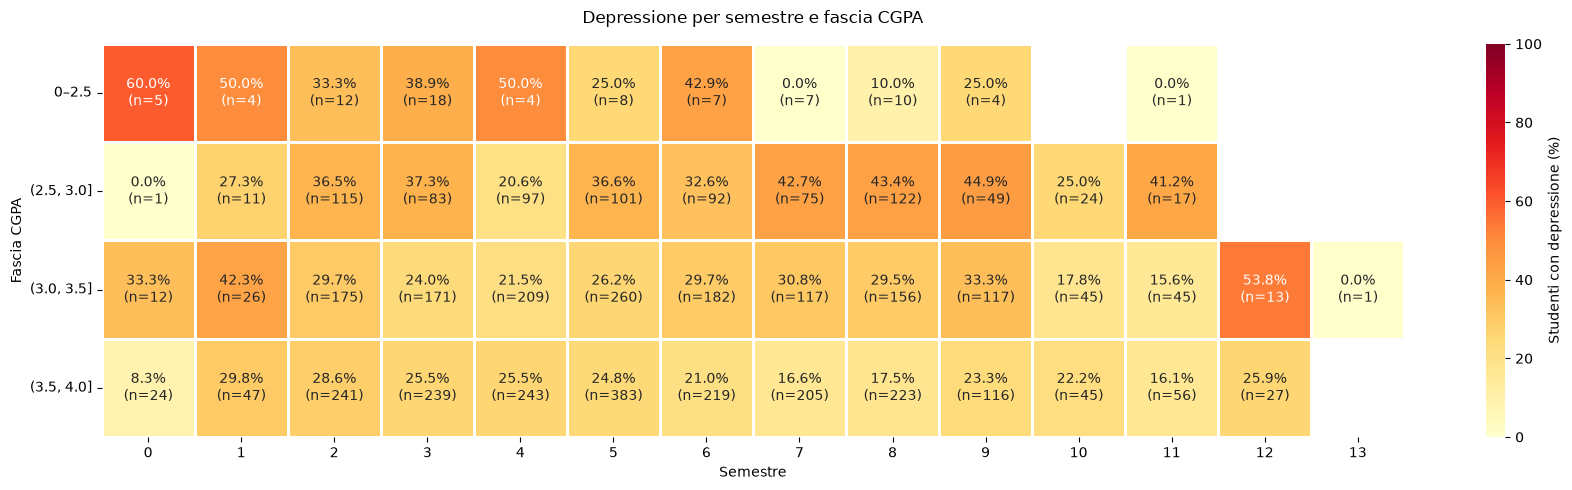

In [106]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d = df.copy()

d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True
)

d = d.dropna(
    subset=["Current_semester", "CGPA_group", "Depression_bin"]
)

# Percentuale e numerosità per ogni combinazione
summary = (
    d.groupby(
        ["CGPA_group", "Current_semester"],
        observed=True
    )
    .agg(
        rate=("Depression_bin", "mean"),
        n=("Depression_bin", "size")
    )
    .reset_index()
)

summary["rate"] *= 100

rates = summary.pivot(
    index="CGPA_group",
    columns="Current_semester",
    values="rate"
).reindex(labels)

counts = summary.pivot(
    index="CGPA_group",
    columns="Current_semester",
    values="n"
).reindex(index=rates.index, columns=rates.columns)

# Ordine numerico dei semestri, anche se memorizzati come "1", "2", ...
# Per etichette come "Semester 1", specificare manualmente l'ordine.
try:
    semester_order = sorted(rates.columns, key=float)
except (ValueError, TypeError):
    semester_order = list(rates.columns)

rates = rates.reindex(columns=semester_order)
counts = counts.reindex(columns=semester_order)

# Testo nelle celle
annotations = pd.DataFrame(
    "",
    index=rates.index,
    columns=rates.columns
)

for row in rates.index:
    for col in rates.columns:
        if pd.notna(rates.loc[row, col]):
            annotations.loc[row, col] = (
                f"{rates.loc[row, col]:.1f}%\n"
                f"(n={int(counts.loc[row, col])})"
            )

fig, ax = plt.subplots(
    figsize=(max(9, 1.25 * len(rates.columns)), 5)
)

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 10},
    cbar_kws={"label": "Studenti con depressione (%)"},
    ax=ax
)

ax.set_title("Depressione per semestre e fascia CGPA", pad=15)
ax.set_xlabel("Semestre")
ax.set_ylabel("Fascia CGPA")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

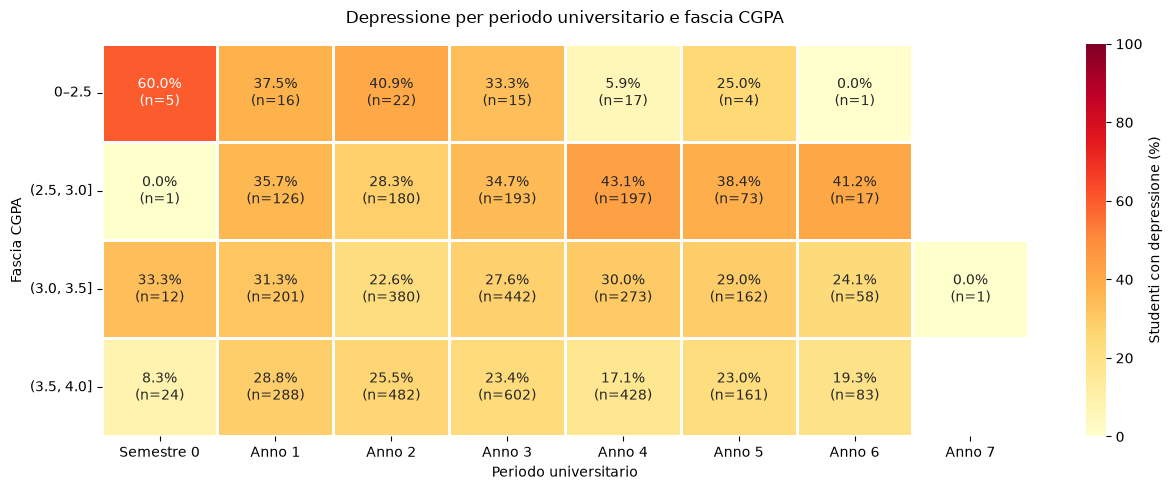

In [107]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d = df.copy()

# Target: Yes → 1, No → 0
d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

# Conversione delle variabili in numerico
d["Current_semester"] = pd.to_numeric(
    d["Current_semester"],
    errors="raise"
)
d["CGPA"] = pd.to_numeric(d["CGPA"], errors="raise")

# Verifica che i semestri siano interi non negativi
semester = d["Current_semester"].dropna()

if ((semester < 0) | (semester % 1 != 0)).any():
    raise ValueError(
        "Current_semester deve contenere numeri interi non negativi."
    )

# Verifica della scala CGPA
if not d["CGPA"].dropna().between(0, 4).all():
    raise ValueError(
        "CGPA contiene valori fuori dall'intervallo 0–4."
    )

# Raggruppamento:
# semestre 0 → gruppo 0, visualizzato come "Semestre 0"
# semestri 1–2 → anno 1
# semestri 3–4 → anno 2
# semestri 5–6 → anno 3
# ...
d["University_year"] = (
    (d["Current_semester"] + 1) // 2
).astype("Int64")

# Fasce di CGPA
labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True,
    right=True
)

# Esclusione dei record mancanti nelle variabili utilizzate
d = d.dropna(
    subset=["University_year", "CGPA_group", "Depression_bin"]
)

if d.empty:
    raise ValueError(
        "Nessuna osservazione disponibile dopo i filtri."
    )

# Percentuale e numerosità per combinazione
summary = (
    d.groupby(
        ["CGPA_group", "University_year"],
        observed=True
    )
    .agg(
        rate=("Depression_bin", "mean"),
        n=("Depression_bin", "size")
    )
    .reset_index()
)

summary["rate"] *= 100

# Matrice delle percentuali
rates = summary.pivot(
    index="CGPA_group",
    columns="University_year",
    values="rate"
).reindex(index=labels)

# Ordine: semestre 0, anno 1, anno 2, ...
year_order = sorted(rates.columns)
rates = rates.reindex(columns=year_order)

# Matrice delle numerosità
counts = summary.pivot(
    index="CGPA_group",
    columns="University_year",
    values="n"
).reindex(
    index=rates.index,
    columns=rates.columns
)

# Annotazioni nelle celle
annotations = pd.DataFrame(
    "",
    index=rates.index,
    columns=rates.columns
)

for row in rates.index:
    for col in rates.columns:
        if pd.notna(rates.loc[row, col]):
            annotations.loc[row, col] = (
                f"{rates.loc[row, col]:.1f}%\n"
                f"(n={int(counts.loc[row, col])})"
            )

# Heatmap
fig, ax = plt.subplots(
    figsize=(max(8, 1.6 * len(rates.columns)), 5)
)

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 10},
    cbar_kws={"label": "Studenti con depressione (%)"},
    ax=ax
)

ax.set_title(
    "Depressione per periodo universitario e fascia CGPA",
    pad=15
)
ax.set_xlabel("Periodo universitario")
ax.set_ylabel("Fascia CGPA")

ax.set_xticklabels(
    [
        "Semestre 0" if year == 0 else f"Anno {int(year)}"
        for year in rates.columns
    ],
    rotation=0
)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [108]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

eda_df = df.copy()

y_eda = (eda_df["Depression"] == "Yes").astype(int)

all_cat_cols = categorical_columns + ["Current_semester"]

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_cat = encoder.fit_transform(eda_df[all_cat_cols])

mi_scores = mutual_info_classif(
    X_cat,
    y_eda,
    discrete_features=True,
    random_state=42
)

mi_table = pd.DataFrame({
    "Variable": all_cat_cols,
    "Mutual_information": mi_scores
}).sort_values("Mutual_information", ascending=False)

print(mi_table.round(4))

              Variable  Mutual_information
5     Health_condition              0.3712
2  Relationship_status              0.0382
3       Marital_status              0.0132
6        friend_circle              0.0052
1    Family_background              0.0046
7        Home_division              0.0040
8     Current_semester              0.0024
4         Living_style              0.0006
0               Gender              0.0000


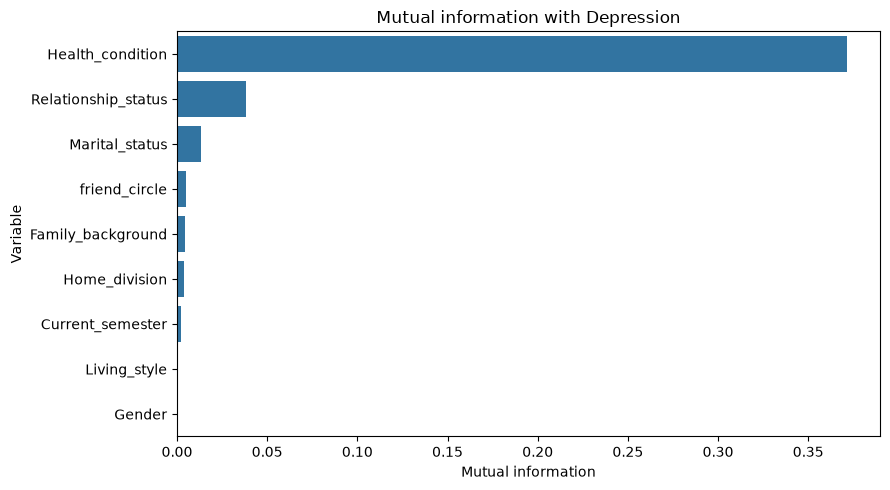

In [109]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=mi_table,
    x="Mutual_information",
    y="Variable",
    color="tab:blue"
)

plt.title("Mutual information with Depression")
plt.xlabel("Mutual information")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

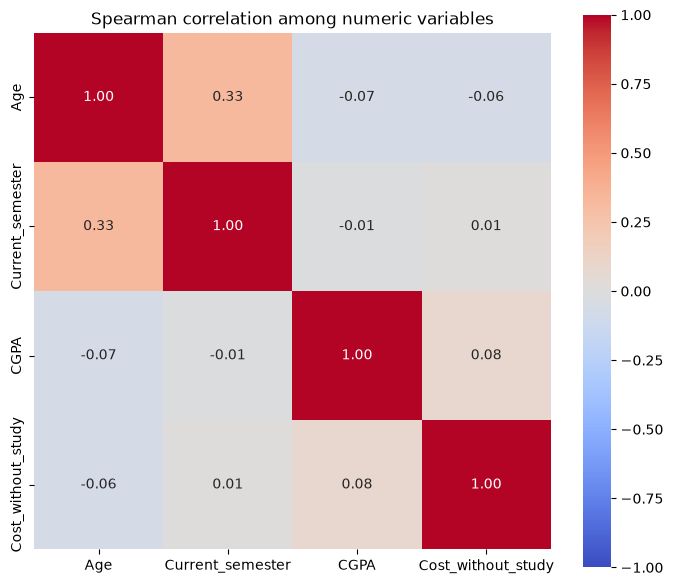

In [110]:
numeric_cols = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

plt.figure(figsize=(7, 6))

sns.heatmap(
    df[numeric_cols].corr(method="pearson"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman correlation among numeric variables")
plt.tight_layout()
plt.show()

In [111]:
display(df.loc[df["Age"] < 18])

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,CGPA_group
72,Male,17,Lower Middle class,Single,Unmarried,Family,1,3.68,Yes,Good,3225,Mymensingh,No,>3.5
166,Female,17,Lower Middle class,Complicated,Unmarried,Bachelor,1,3.33,Yes,Good,9621,Rangpur,No,3.0-3.5
180,Male,17,Middle class,Single,Unmarried,Family,0,3.50,Yes,Abnormal,17272,Dhaka,Yes,3.0-3.5
199,Female,17,Lower Middle class,In a Relationship,Unmarried,Bachelor,3,3.90,Yes,Good,1880,Rangpur,No,>3.5
408,Female,17,Rich class,Single,Unmarried,Bachelor,1,3.58,Yes,Normal,27068,Khulna,No,>3.5
420,Female,17,Lower Middle class,In a Relationship,Unmarried,Family,4,4.00,Yes,Good,9033,Sylhet,No,>3.5
446,Female,17,Middle class,Single,Unmarried,Bachelor,1,3.50,No,Good,13455,Rangpur,No,3.0-3.5
600,Male,17,Lower Middle class,In a Relationship,Unmarried,Bachelor,2,3.50,No,Good,6474,Chittagong,No,3.0-3.5
3441,Male,17,Middle class,Single,Unmarried,Family,2,2.80,Yes,Abnormal,15000,Mymensingh,Yes,2.5-3.0
3464,Female,17,Lower Middle class,In a Relationship,Unmarried,Family,2,3.41,No,Critical,10000,Mymensingh,Yes,3.0-3.5


In [112]:
subset = df.loc[
    (df["Marital_status"] == "Married") &
    (df["Relationship_status"] == "Single")
]

display(subset.describe(include="all"))


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,CGPA_group
count,201,201.000000,201,201,201,201,201.000000,201.000000,201,201,201.000000,201,201,201
unique,2,NaN,3,1,1,2,NaN,NaN,2,4,NaN,8,2,3
top,Male,NaN,Middle class,Single,Married,Bachelor,NaN,NaN,Yes,Normal,NaN,Khulna,No,>3.5
freq,123,NaN,127,201,201,140,NaN,NaN,132,66,NaN,52,153,108
mean,NaN,23.139303,NaN,NaN,NaN,NaN,5.885572,3.446915,NaN,NaN,14672.124378,NaN,NaN,NaN
std,NaN,2.360190,NaN,NaN,NaN,NaN,2.800329,0.355140,NaN,NaN,6818.869214,NaN,NaN,NaN
min,NaN,18.000000,NaN,NaN,NaN,NaN,0.000000,2.570000,NaN,NaN,134.000000,NaN,NaN,NaN
25%,NaN,21.000000,NaN,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,10703.000000,NaN,NaN,NaN
50%,NaN,23.000000,NaN,NaN,NaN,NaN,6.000000,3.550000,NaN,NaN,14687.000000,NaN,NaN,NaN
75%,NaN,25.000000,NaN,NaN,NaN,NaN,8.000000,3.750000,NaN,NaN,18436.000000,NaN,NaN,NaN


### CLUSTER ANALYSIS

In [ ]:
import gower
from sklearn.cluster import DBSCAN
 
D = gower.gower_matrix(df)    # df con colonne numeriche e categoriche

labels = DBSCAN(eps=0.15, min_samples=10, metric="precomputed").fit_predict(D)

In [73]:
import numpy as np
import pandas as pd

# Gower restituisce spesso float32: convertila in float64 per sicurezza
D64 = np.asarray(D, dtype=np.float64)

# Controlli rapidi
assert D64.shape[0] == D64.shape[1], "La matrice deve essere quadrata"
assert np.allclose(D64, D64.T), "La matrice deve essere simmetrica"
assert not np.isnan(D64).any(), "La matrice non deve contenere NaN"
assert D64.min() >= 0, "Le distanze non possono essere negative"

print("Matrice Gower pronta:", D64.shape, D64.dtype)

Matrice Gower pronta: (4464, 4464) float64


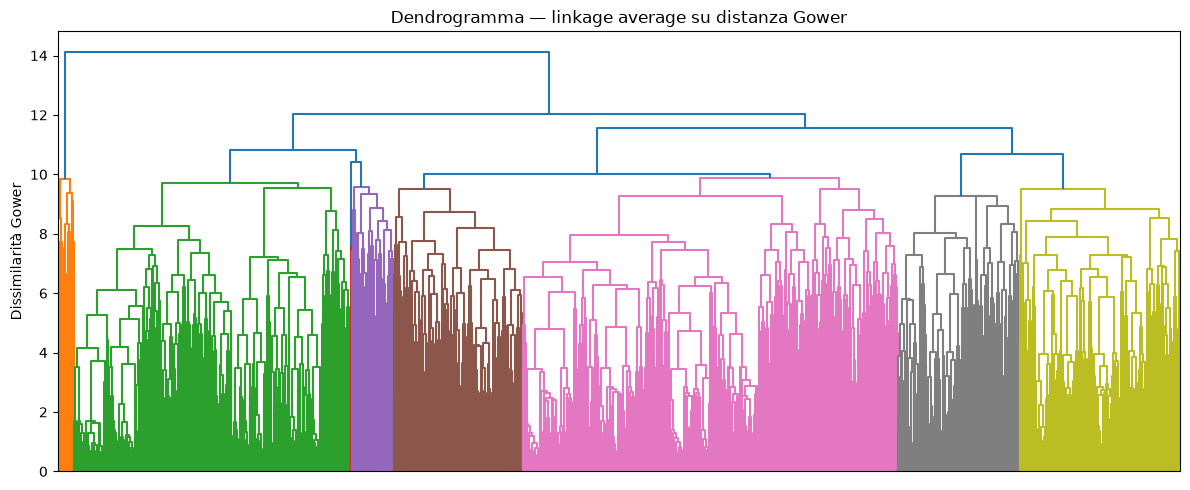

0    1465
1    2999
Name: count, dtype: int64


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Average linkage è spesso una scelta robusta con matrici di distanza arbitrarie
Z = linkage(D, method="average")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="level", p=25, no_labels=True)
plt.title("Dendrogramma — linkage complete su distanza Gower")
plt.ylabel("Dissimilarità Gower")
plt.tight_layout()
plt.show()

# Scegli il numero di cluster dopo aver guardato il dendrogramma
agg = AgglomerativeClustering(
    n_clusters=2,
    metric="precomputed",
    linkage="complete"
)
labels_agg = agg.fit_predict(D)

df_ready["cluster_hierarchical"] = labels_agg
print(pd.Series(labels_agg).value_counts().sort_index())

In [122]:
from sklearn.metrics import silhouette_score

for k in range(2, 10):
    model = AgglomerativeClustering(
        n_clusters=k,
        metric="precomputed",
        linkage="complete"
    )
    lab = model.fit_predict(D)
    score = silhouette_score(D, lab, metric="precomputed")
    print(k, round(score, 3))

2 0.149
3 0.101
4 0.07
5 0.054
6 0.042
7 0.044
8 0.06
9 0.051


In [123]:
K = 2 # sostituiscilo con il valore scelto

final_model = AgglomerativeClustering(
    n_clusters=K,
    metric="precomputed",
    linkage="complete"
)

labels_hier = final_model.fit_predict(D64)

df_ready["cluster_hierarchical"] = labels_hier

print(df_ready["cluster_hierarchical"].value_counts().sort_index())

cluster_hierarchical
0    1465
1    2999
Name: count, dtype: int64


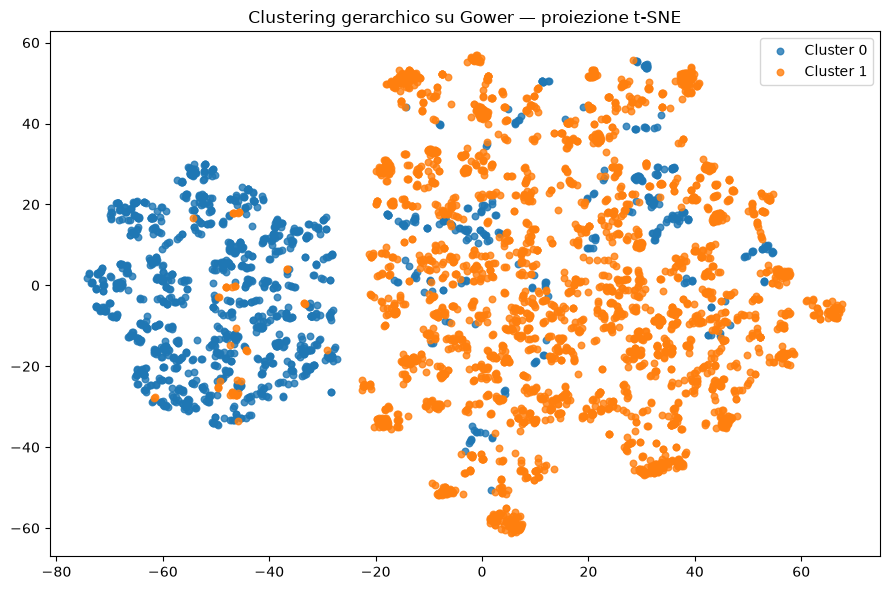

In [124]:
from sklearn.manifold import TSNE

embedding = TSNE(
    n_components=2,
    metric="precomputed",
    init="random",
    perplexity=30,
    random_state=42
).fit_transform(D64)

plt.figure(figsize=(9, 6))

for cluster in sorted(np.unique(labels_hier)):
    mask = labels_hier == cluster
    plt.scatter(
        embedding[mask, 0],
        embedding[mask, 1],
        s=22,
        alpha=0.8,
        label=f"Cluster {cluster}"
    )

plt.title("Clustering gerarchico su Gower — proiezione t-SNE")
plt.legend()
plt.tight_layout()
plt.show()

In [125]:
# Profilo numerico
profile_num = (
    df_ready
    .groupby("cluster_hierarchical")
    .mean(numeric_only=True)
    .round(2)
)
print(profile_num)

# Profilo categorico
cat_cols = df_ready.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    if col != "cluster_hierarchical":
        print(f"\n--- {col} ---")
        print(
            pd.crosstab(
                df_ready["cluster_hierarchical"],
                df_ready[col],
                normalize="index"
            ).round(2)
        )

                        Age  Current_semester  CGPA  Cost_without_study
cluster_hierarchical                                                   
0                     22.58              5.28  3.36            11221.81
1                     22.64              5.46  3.44            11253.32

--- Gender ---
Gender                Female  Male
cluster_hierarchical              
0                       0.45  0.55
1                       0.60  0.40

--- Family_background ---
Family_background     Lower Middle class  Middle class  Rich class
cluster_hierarchical                                              
0                                   0.30          0.61        0.09
1                                   0.24          0.58        0.18

--- Relationship_status ---
Relationship_status   Complicated  In a Relationship  Single
cluster_hierarchical                                        
0                            0.04               0.16    0.80
1                            0.05               0

### REGRESSIONE LOGISTICA

In [139]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
TARGET = "Depression"

# Variabili indipendenti
num_cols = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

cat_cols = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Home_division"
]

# Variabile esclusa per possibile data leakage / separazione perfetta
excluded_cols = ["Health_condition"]

print("Variabili numeriche:", num_cols)
print("Variabili categoriche:", cat_cols)
print("Variabili escluse:", excluded_cols)

Variabili numeriche: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Variabili categoriche: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Home_division']
Variabili escluse: ['Health_condition']


In [140]:
df_model = df_ready.copy()

# Rimuove eventuali colonne di clustering o non necessarie
cols_to_drop = [
    col for col in df_model.columns
    if col.startswith("cluster")
]
df_model = df_model.drop(columns=cols_to_drop, errors="ignore")

# Mantiene solo le colonne utili
needed_cols = [TARGET] + num_cols + cat_cols
df_model = df_model[needed_cols].copy()

# Rimuove righe incomplete
df_model = df_model.dropna(subset=needed_cols).copy()

# Codifica del target binario
df_model[TARGET] = (
    df_model[TARGET]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

print("Distribuzione del target:")
print(df_model[TARGET].value_counts(dropna=False))

if df_model[TARGET].isna().any():
    raise ValueError(
        "Il target contiene valori non riconosciuti. "
        "Attesi: Yes / No."
    )

df_model[TARGET] = df_model[TARGET].astype(int)

print("\nDimensioni finali:", df_model.shape)

Distribuzione del target:
Depression
0    3263
1    1201
Name: count, dtype: int64

Dimensioni finali: (4464, 12)


In [141]:
train_df, test_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_model[TARGET]
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nDistribuzione target nel train:")
print(train_df[TARGET].value_counts(normalize=True).round(3))

print("\nDistribuzione target nel test:")
print(test_df[TARGET].value_counts(normalize=True).round(3))

Train: (3571, 12)
Test: (893, 12)

Distribuzione target nel train:
Depression
0    0.731
1    0.269
Name: proportion, dtype: float64

Distribuzione target nel test:
Depression
0    0.731
1    0.269
Name: proportion, dtype: float64


In [142]:
# Standardizzazione delle numeriche: fit solo sul training set
scaler = StandardScaler()

train_df[num_cols] = scaler.fit_transform(train_df[num_cols])
test_df[num_cols] = scaler.transform(test_df[num_cols])

# One-hot encoding delle categoriche
train_X = pd.get_dummies(
    train_df[num_cols + cat_cols],
    columns=cat_cols,
    drop_first=True,
    dtype=float
)

test_X = pd.get_dummies(
    test_df[num_cols + cat_cols],
    columns=cat_cols,
    drop_first=True,
    dtype=float
)

# Allinea le colonne del test a quelle del train
test_X = test_X.reindex(columns=train_X.columns, fill_value=0)

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

# Intercetta per statsmodels
X_train = sm.add_constant(train_X, has_constant="add")
X_test = sm.add_constant(test_X, has_constant="add")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nColonne finali:")
print(X_train.columns.tolist())

X_train: (3571, 21)
X_test: (893, 21)

Colonne finali:
['const', 'Age', 'Current_semester', 'CGPA', 'Cost_without_study', 'Gender_Male', 'Family_background_Middle class', 'Family_background_Rich class', 'Relationship_status_In a Relationship', 'Relationship_status_Single', 'Marital_status_Separated', 'Marital_status_Unmarried', 'Living_style_Family', 'friend_circle_Yes', 'Home_division_Chittagong', 'Home_division_Dhaka', 'Home_division_Khulna', 'Home_division_Mymensingh', 'Home_division_Rajshahi', 'Home_division_Rangpur', 'Home_division_Sylhet']


In [158]:
def fit_logit(X, y):
    X = X.copy()
    y = y.copy()

    # Rimuove colonne duplicate
    X = X.loc[:, ~X.columns.duplicated()]

    # Forza tipi numerici
    X = X.apply(pd.to_numeric, errors="coerce").astype(float)
    X = X.replace([np.inf, -np.inf], np.nan)

    # CORREZIONE: Rimuove le colonne costanti MA MANTIENE SEMPRE "const"
    cols_to_keep = [
        col for col in X.columns 
        if col == "const" or X[col].nunique(dropna=False) > 1
    ]
    X = X[cols_to_keep]

    y = pd.to_numeric(y, errors="coerce")

    valid = X.notna().all(axis=1) & y.notna()
    X = X.loc[valid]
    y = y.loc[valid].astype(int)

    if y.nunique() < 2 or X.shape[1] == 0:
        return None

    methods = ["newton", "lbfgs", "bfgs"]

    for method in methods:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = sm.Logit(y, X).fit(
                    method=method,
                    maxiter=500,
                    disp=0
                )

            if model.mle_retvals.get("converged", False):
                return model

        except Exception:
            continue

    return None


def get_criterion(model, criterion_name):
    """Restituisce AIC o BIC; infinito se il modello non è valido."""
    if model is None:
        return np.inf

    criterion_name = criterion_name.lower()

    if criterion_name not in ["aic", "bic"]:
        raise ValueError("criterion_name deve essere 'aic' oppure 'bic'")

    return float(getattr(model, criterion_name))

In [144]:
def forward_selection(
    X_train,
    y_train,
    criterion_name="aic",
    verbose=True
):
    """
    Forward selection basata su AIC oppure BIC.
    """
    predictors = [
        col for col in X_train.columns
        if col != "const"
    ]

    selected = []
    remaining = predictors.copy()

    # Modello iniziale: solo intercetta
    current_model = fit_logit(X_train[["const"]], y_train)
    current_score = get_criterion(current_model, criterion_name)
    best_model = current_model

    while remaining:
        trials = []

        for candidate in remaining:
            cols = ["const"] + selected + [candidate]

            model = fit_logit(X_train[cols], y_train)
            score = get_criterion(model, criterion_name)

            trials.append((score, candidate, model))

        trials.sort(key=lambda x: x[0])

        best_trial_score, best_candidate, best_trial_model = trials[0]

        if best_trial_score < current_score - 1e-6:
            selected.append(best_candidate)
            remaining.remove(best_candidate)

            current_score = best_trial_score
            best_model = best_trial_model

            if verbose:
                print(
                    f"[FORWARD] + {best_candidate:<40} "
                    f"{criterion_name.upper()} = {best_trial_score:.3f}"
                )
        else:
            break

    return selected, best_model, current_score

In [145]:
def backward_elimination(
    X_train,
    y_train,
    criterion_name="aic",
    verbose=True
):
    """
    Backward elimination basata su AIC oppure BIC.
    """
    selected = [
        col for col in X_train.columns
        if col != "const"
    ]

    current_model = fit_logit(
        X_train[["const"] + selected],
        y_train
    )

    current_score = get_criterion(current_model, criterion_name)
    best_model = current_model

    while len(selected) > 1:
        trials = []

        for candidate in selected:
            trial_vars = [
                col for col in selected
                if col != candidate
            ]

            model = fit_logit(
                X_train[["const"] + trial_vars],
                y_train
            )

            score = get_criterion(model, criterion_name)
            trials.append((score, candidate, model))

        trials.sort(key=lambda x: x[0])

        best_trial_score, candidate_to_remove, best_trial_model = trials[0]

        if best_trial_score < current_score - 1e-6:
            selected.remove(candidate_to_remove)

            current_score = best_trial_score
            best_model = best_trial_model

            if verbose:
                print(
                    f"[BACKWARD] - {candidate_to_remove:<40} "
                    f"{criterion_name.upper()} = {best_trial_score:.3f}"
                )
        else:
            break

    return selected, best_model, current_score

In [146]:
results = {}

for method in ["forward", "backward"]:
    for criterion_name in ["aic", "bic"]:
        key = f"{method}_{criterion_name}"

        print(f"\n{'=' * 70}")
        print(f"{method.upper()} SELECTION — {criterion_name.upper()}")
        print(f"{'=' * 70}")

        if method == "forward":
            variables, model, score = forward_selection(
                X_train,
                y_train,
                criterion_name=criterion_name,
                verbose=True
            )
        else:
            variables, model, score = backward_elimination(
                X_train,
                y_train,
                criterion_name=criterion_name,
                verbose=True
            )

        results[key] = {
            "variables": variables,
            "model": model,
            "score": score
        }


FORWARD SELECTION — AIC
[FORWARD] + Relationship_status_In a Relationship    AIC = 4120.711
[FORWARD] + friend_circle_Yes                        AIC = 3882.010
[FORWARD] + Gender_Male                              AIC = 3850.537
[FORWARD] + CGPA                                     AIC = 3819.848
[FORWARD] + Home_division_Dhaka                      AIC = 3796.446
[FORWARD] + Family_background_Rich class             AIC = 3784.151
[FORWARD] + Cost_without_study                       AIC = 3752.006
[FORWARD] + Marital_status_Unmarried                 AIC = 3734.602
[FORWARD] + Family_background_Middle class           AIC = 3711.792
[FORWARD] + Relationship_status_Single               AIC = 3697.965
[FORWARD] + Home_division_Mymensingh                 AIC = 3697.576
[FORWARD] + Home_division_Sylhet                     AIC = 3696.985

FORWARD SELECTION — BIC
[FORWARD] + Relationship_status_In a Relationship    BIC = 4126.891
[FORWARD] + friend_circle_Yes                        BIC = 3894.37

In [147]:
summary_rows = []

for key, result in results.items():
    model = result["model"]

    summary_rows.append({
        "Metodo": key.replace("_", " ").title(),
        "N. variabili": len(result["variables"]),
        "AIC train": np.nan if model is None else round(model.aic, 2),
        "BIC train": np.nan if model is None else round(model.bic, 2),
        "Variabili selezionate": (
            ", ".join(result["variables"])
            if result["variables"]
            else "Nessuna"
        )
    })

summary = pd.DataFrame(summary_rows)

print("\nRiepilogo dei modelli:")
print(summary.to_string(index=False))


Riepilogo dei modelli:
      Metodo  N. variabili  AIC train  BIC train                                                                                                                                                                                                                                                                    Variabili selezionate
 Forward Aic            12    3696.98    3771.15 Relationship_status_In a Relationship, friend_circle_Yes, Gender_Male, CGPA, Home_division_Dhaka, Family_background_Rich class, Cost_without_study, Marital_status_Unmarried, Family_background_Middle class, Relationship_status_Single, Home_division_Mymensingh, Home_division_Sylhet
 Forward Bic            10    3697.97    3759.77                                                 Relationship_status_In a Relationship, friend_circle_Yes, Gender_Male, CGPA, Home_division_Dhaka, Family_background_Rich class, Cost_without_study, Marital_status_Unmarried, Family_background_Middle class, Relationship_

In [ ]:
# Scegli il criterio per il modello finale:
# "aic" privilegia l'adattamento;
# "bic" privilegia modelli più parsimoniosi.
final_criterion = "bic"

valid_results = {
    key: result
    for key, result in results.items()
    if result["model"] is not None
}

if not valid_results:
    raise RuntimeError(
        "Nessun modello logit è stato stimato con successo."
    )

best_key = min(
    valid_results,
    key=lambda key: get_criterion(
        valid_results[key]["model"],
        final_criterion
    )
)

best_result = valid_results[best_key]
best_vars = best_result["variables"]
best_model = best_result["model"]

print(f"\nModello selezionato: {best_key}")
print(f"Criterio: {final_criterion.upper()}")
print(f"Numero variabili: {len(best_vars)}")
print(f"Variabili finali:\n{best_vars}")

print("\nRiepilogo del modello:")
print(best_model.summary())


Modello selezionato: forward_bic
Criterio: BIC
Numero variabili: 10
Variabili finali:
['Relationship_status_In a Relationship', 'friend_circle_Yes', 'Gender_Male', 'CGPA', 'Home_division_Dhaka', 'Family_background_Rich class', 'Cost_without_study', 'Marital_status_Unmarried', 'Family_background_Middle class', 'Relationship_status_Single']

Riepilogo del modello:
                           Logit Regression Results                           
Dep. Variable:             Depression   No. Observations:                 3571
Model:                          Logit   Df Residuals:                     3561
Method:                           MLE   Df Model:                            9
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                  0.1157
Time:                        12:30:39   Log-Likelihood:                -1839.0
converged:                       True   LL-Null:                       -2079.7
Covariance Type:            nonrobust   LLR p-value:                 5.649e-98
  

In [159]:
best_result = valid_results[best_key]
best_vars = best_result["variables"]

# Ristima robusta del modello migliore sulle sole variabili selezionate
best_model = fit_logit(X_train[["const"] + best_vars], y_train)

if best_model is None:
    raise RuntimeError("Il modello migliore non è riuscito a convergere durante la ristima.")

print(f"\nModello selezionato: {best_key}")
print(f"Criterio: {final_criterion.upper()}")
print(f"Numero variabili: {len(best_vars)}")
print(f"Variabili finali:\n{best_vars}")

print("\nRiepilogo del modello:")
print(best_model.summary())

# Prepara il test set con esattamente le stesse variabili del modello migliore
X_test_best = X_test[["const"] + best_vars].copy()

# Sicurezza: rimuove duplicati e allinea le colonne
X_test_best = X_test_best.loc[:, ~X_test_best.columns.duplicated()]
X_test_best = X_test_best.reindex(
    columns=["const"] + best_vars,
    fill_value=0
).astype(float)

# Probabilità e classi predette
y_prob = best_model.predict(X_test_best)
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))


Modello selezionato: forward_bic
Criterio: BIC
Numero variabili: 10
Variabili finali:
['Relationship_status_In a Relationship', 'friend_circle_Yes', 'Gender_Male', 'CGPA', 'Home_division_Dhaka', 'Family_background_Rich class', 'Cost_without_study', 'Marital_status_Unmarried', 'Family_background_Middle class', 'Relationship_status_Single']

Riepilogo del modello:
                           Logit Regression Results                           
Dep. Variable:             Depression   No. Observations:                 3571
Model:                          Logit   Df Residuals:                     3560
Method:                           MLE   Df Model:                           10
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                  0.1225
Time:                        12:40:20   Log-Likelihood:                -1824.9
converged:                       True   LL-Null:                       -2079.7
Covariance Type:            nonrobust   LLR p-value:                4.211e-103
  

In [160]:
# Odds ratio
odds_ratios = np.exp(best_model.params)

results_or = pd.DataFrame({
    "Coefficiente": best_model.params,
    "Odds Ratio": odds_ratios,
    "p-value": best_model.pvalues
}).sort_values("p-value")

print(results_or.round(4))

                                       Coefficiente  Odds Ratio  p-value
Cost_without_study                           0.4430      1.5574   0.0000
Family_background_Rich class                -1.4939      0.2245   0.0000
CGPA                                        -0.2674      0.7654   0.0000
Gender_Male                                 -0.5746      0.5630   0.0000
Relationship_status_Single                   1.3978      4.0461   0.0000
const                                       -1.3688      0.2544   0.0000
Marital_status_Unmarried                     0.6003      1.8227   0.0000
friend_circle_Yes                           -0.3936      0.6746   0.0000
Home_division_Dhaka                         -0.3807      0.6834   0.0000
Family_background_Middle class              -0.4132      0.6615   0.0001
Relationship_status_In a Relationship       -0.2328      0.7923   0.3629


Fattori che Aumentano la Probabilità (Odds Ratio > 1):
Relationship_status_Single (OR = 4.05, p < 0.001): È il predittore con l'impatto positivo più forte. Essere single aumenta l'odds dell'evento di oltre 4 volte rispetto alla categoria di riferimento.
Marital_status_Unmarried (OR = 1.82, p < 0.001): Incrementa l'odds di circa l'82%.
Cost_without_study (OR = 1.56, p < 0.001): Aumenta l'odds di circa il 56%, indicando un peso rilevante dei costi indipendenti dagli studi.

Fattori che Riducono la Probabilità (Odds Ratio < 1)
Queste variabili hanno un coefficiente negativo e riducono l'odds dell'evento:
Family_background_Rich class (OR = 0.22, p < 0.001): Mostra la riduzione più forte in assoluto. Appartenere a una famiglia di classe ricca riduce drasticamente l'odds dell'evento rispetto alla classe di riferimento.
Gender_Male (OR = 0.56, p < 0.001): I soggetti di sesso maschile presentano un odds inferiore del circa 44% rispetto al gruppo di riferimento femminile.
CGPA (OR = 0.77, p < 0.001): Un incremento del CGPA è associato a una riduzione dell'odds (circa del 23% per unità).
Family_background_Middle class (OR = 0.66, p = 0.0001): Riduce l'odds di circa il 34% rispetto alla categoria di base.
friend_circle_Yes (OR = 0.67, p < 0.001): La presenza di una cerchia di amici riduce l'odds di circa il 32%.
Home_division_Dhaka (OR = 0.68, p < 0.001): Vivere nella divisione di Dhaka riduce l'odds di circa il 32%.

### MODELLO DI ALBERO DI CLASSIFICAZIONE

1. Import e configurazione

In [174]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42
TARGET = "Depression"

num_cols = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

cat_cols = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Home_division"
]

# Variabile esclusa: separa perfettamente il target
excluded_cols = ["Health_condition"]

print("Target:", TARGET)
print("Numeriche:", num_cols)
print("Categoriche:", cat_cols)
print("Escluse:", excluded_cols)

Target: Depression
Numeriche: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categoriche: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Home_division']
Escluse: ['Health_condition']


2. Preparazione del dataset

In [175]:
df_tree = df_ready.copy()

# Rimuove eventuali colonne di clustering
cluster_cols = [
    col for col in df_tree.columns
    if col.startswith("cluster")
]
df_tree = df_tree.drop(columns=cluster_cols, errors="ignore")

# Seleziona solo le colonne necessarie
needed_cols = [TARGET] + num_cols + cat_cols
df_tree = df_tree[needed_cols].copy()

# Rimuove righe incomplete
df_tree = df_tree.dropna(subset=needed_cols).copy()

# Codifica del target
df_tree[TARGET] = (
    df_tree[TARGET]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

print("Distribuzione del target:")
print(df_tree[TARGET].value_counts(dropna=False))

if df_tree[TARGET].isna().any():
    raise ValueError("Il target contiene valori diversi da Yes/No.")

df_tree[TARGET] = df_tree[TARGET].astype(int)

print("\nDimensioni dataset:", df_tree.shape)

Distribuzione del target:
Depression
0    3263
1    1201
Name: count, dtype: int64

Dimensioni dataset: (4464, 12)


3. Train/test split

In [176]:
X = df_tree[num_cols + cat_cols]
y = df_tree[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistribuzione target nel train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuzione target nel test:")
print(y_test.value_counts(normalize=True).round(3))

Train: (3571, 11)
Test: (893, 11)

Distribuzione target nel train:
Depression
0    0.731
1    0.269
Name: proportion, dtype: float64

Distribuzione target nel test:
Depression
0    0.731
1    0.269
Name: proportion, dtype: float64


4. Encoding delle variabili categoriche

Per un albero non serve standardizzare Age, CGPA, ecc.: gli split sono basati su soglie e non sulla scala delle variabili. Le categoriche invece vanno trasformate in dummy

In [177]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=cat_cols,
    drop_first=True,
    dtype=float
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=cat_cols,
    drop_first=True,
    dtype=float
)

# Allinea le colonne del test a quelle del train
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("X_train encoded:", X_train_encoded.shape)
print("X_test encoded:", X_test_encoded.shape)
print("\nFeature finali:")
print(X_train_encoded.columns.tolist())

X_train encoded: (3571, 20)
X_test encoded: (893, 20)

Feature finali:
['Age', 'Current_semester', 'CGPA', 'Cost_without_study', 'Gender_Male', 'Family_background_Middle class', 'Family_background_Rich class', 'Relationship_status_In a Relationship', 'Relationship_status_Single', 'Marital_status_Separated', 'Marital_status_Unmarried', 'Living_style_Family', 'friend_circle_Yes', 'Home_division_Chittagong', 'Home_division_Dhaka', 'Home_division_Khulna', 'Home_division_Mymensingh', 'Home_division_Rajshahi', 'Home_division_Rangpur', 'Home_division_Sylhet']


5. Albero baseline

max_depth=3 e min_samples_leaf=20 limitano fin da subito la complessità e riducono l’overfitting; poi ottimizzeremo questi parametri con cross-validation.

In [178]:
baseline_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=20,
    class_weight="balanced",  ##### aggiunta in un secondo momento
    random_state=RANDOM_STATE,
)

baseline_tree.fit(X_train_encoded, y_train)

y_pred_baseline = baseline_tree.predict(X_test_encoded)
y_prob_baseline = baseline_tree.predict_proba(X_test_encoded)[:, 1]

print("Baseline tree — Test set")
print("Accuracy:", round(accuracy_score(y_test, y_pred_baseline), 3))
print("Precision:", round(precision_score(y_test, y_pred_baseline), 3))
print("Recall:", round(recall_score(y_test, y_pred_baseline), 3))
print("F1-score:", round(f1_score(y_test, y_pred_baseline), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_baseline), 3))

Baseline tree — Test set
Accuracy: 0.559
Precision: 0.351
Recall: 0.754
F1-score: 0.479
ROC-AUC: 0.652


6. Ottimizzazione degli iperparametri

GridSearchCV con un classificatore usa folds stratificati, così ogni fold conserva circa le stesse proporzioni delle classi del target.

In [ ]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 5, 10, 20, 30],
    "ccp_alpha": [0.0, 0.001, 0.005, 0.01, 0.02]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ), 
    param_grid=param_grid,
    scoring="f1",  # o 'roc_auc'
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

grid_search.fit(X_train_encoded, y_train)

print("Migliori iperparametri:")
print(grid_search.best_params_)

print("\nMiglior ROC-AUC in cross-validation:")
print(round(grid_search.best_score_, 3))

Fitting 5 folds for each of 1600 candidates, totalling 8000 fits
Migliori iperparametri:
{'ccp_alpha': 0.001, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}

Miglior ROC-AUC in cross-validation:
0.516


7. Modello finale

In [187]:
best_tree = grid_search.best_estimator_

y_pred = best_tree.predict(X_test_encoded)
y_prob = best_tree.predict_proba(X_test_encoded)[:, 1]

print("Modello finale — Test set")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Modello finale — Test set
Accuracy: 0.62
Precision: 0.381
Recall: 0.658
F1-score: 0.482
ROC-AUC: 0.687

Confusion matrix:
[[396 257]
 [ 82 158]]

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.61      0.70       653
           1       0.38      0.66      0.48       240

    accuracy                           0.62       893
   macro avg       0.60      0.63      0.59       893
weighted avg       0.71      0.62      0.64       893



8. Curva ROC

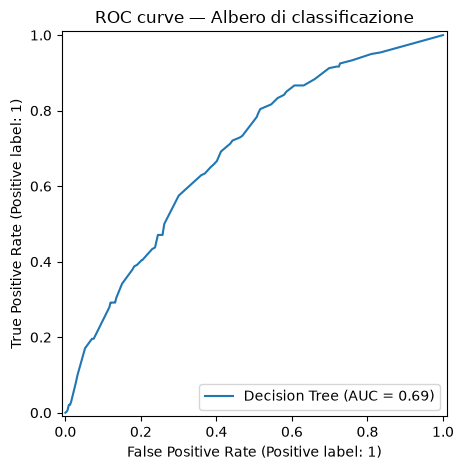

In [188]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Decision Tree"
)

plt.title("ROC curve — Albero di classificazione")
plt.tight_layout()
plt.show()

9. Visualizzazione dell’albero


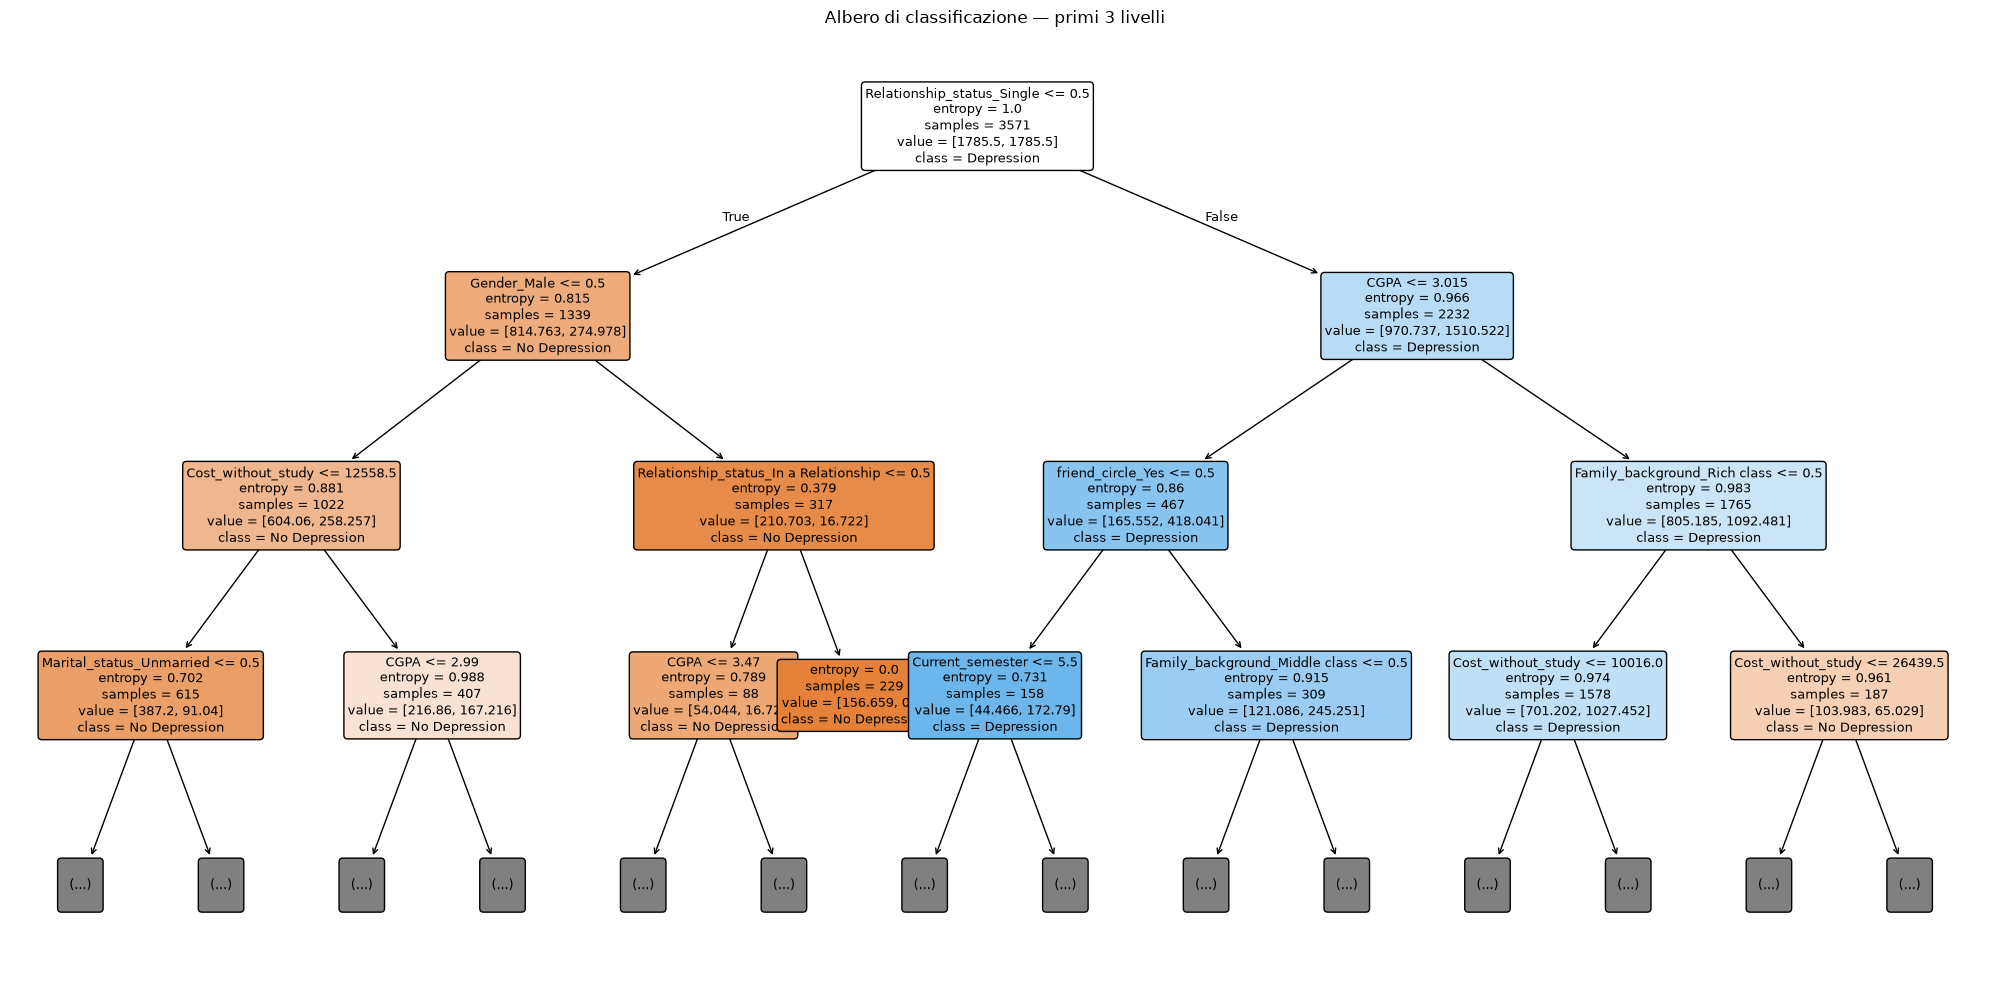

In [182]:
plt.figure(figsize=(20, 10))

plot_tree(
    best_tree,
    feature_names=X_train_encoded.columns,
    class_names=["No Depression", "Depression"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Albero di classificazione — primi 3 livelli")
plt.tight_layout()
plt.show()

10. Importanza delle variabili

Le importanze sono calcolate come riduzione normalizzata dell’impurezza apportata da ciascuna feature; sono utili, ma possono favorire variabili con molte categorie o valori distinti.

                                  Feature  Importance
8              Relationship_status_Single    0.287582
3                      Cost_without_study    0.158077
2                                    CGPA    0.142888
4                             Gender_Male    0.062593
0                                     Age    0.052878
1                        Current_semester    0.051328
5          Family_background_Middle class    0.048039
10               Marital_status_Unmarried    0.041693
6            Family_background_Rich class    0.032355
7   Relationship_status_In a Relationship    0.030418
12                      friend_circle_Yes    0.029730
15                   Home_division_Khulna    0.022840
18                  Home_division_Rangpur    0.015727
14                    Home_division_Dhaka    0.013005
17                 Home_division_Rajshahi    0.010850


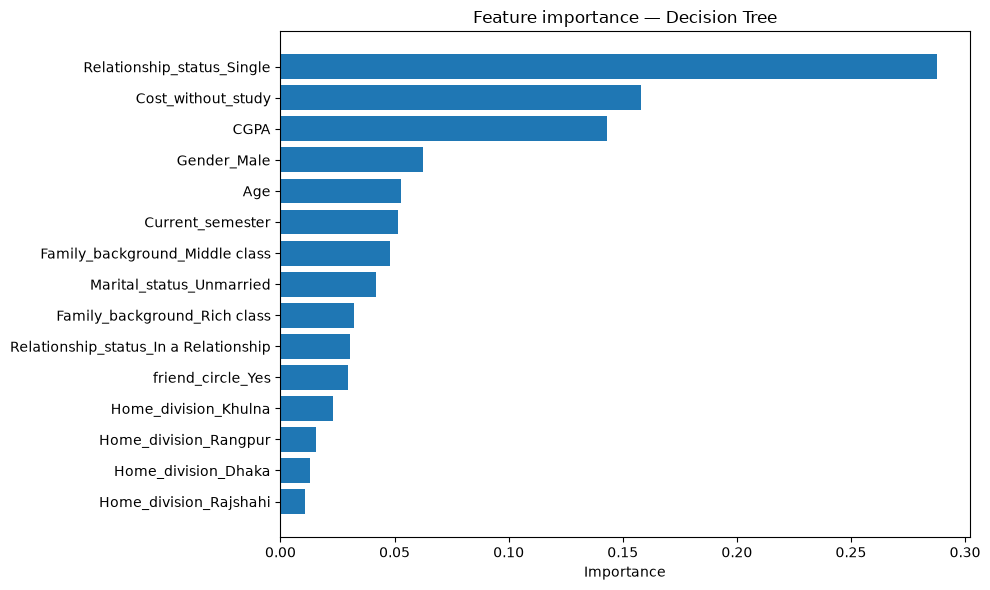

In [183]:
importances = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": best_tree.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print(importances.head(15))

plt.figure(figsize=(10, 6))
plt.barh(
    importances.head(15)["Feature"][::-1],
    importances.head(15)["Importance"][::-1]
)
plt.xlabel("Importance")
plt.title("Feature importance — Decision Tree")
plt.tight_layout()
plt.show()

11. Regole dell’albero

In [184]:
from sklearn.tree import export_text

tree_rules = export_text(
    best_tree,
    feature_names=list(X_train_encoded.columns),
    max_depth=4
)

print(tree_rules)

|--- Relationship_status_Single <= 0.50
|   |--- Gender_Male <= 0.50
|   |   |--- Cost_without_study <= 12558.50
|   |   |   |--- Marital_status_Unmarried <= 0.50
|   |   |   |   |--- Family_background_Middle class <= 0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- Family_background_Middle class >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- Marital_status_Unmarried >  0.50
|   |   |   |   |--- Family_background_Rich class <= 0.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- Family_background_Rich class >  0.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |--- Cost_without_study >  12558.50
|   |   |   |--- CGPA <= 2.99
|   |   |   |   |--- class: 1
|   |   |   |--- CGPA >  2.99
|   |   |   |   |--- Current_semester <= 4.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- Current_semester >  4.50
|   |   |   |   |   |--- truncated branch of depth 5
|   |--- Gender_Male >  0.

12. Predizione su un nuovo caso

In [185]:
new_student = pd.DataFrame({
    "Age": [21],
    "Current_semester": [6],
    "CGPA": [3.10],
    "Cost_without_study": [120],
    "Gender": ["Male"],
    "Family_background": ["Middle class"],
    "Relationship_status": ["Single"],
    "Marital_status": ["Unmarried"],
    "Living_style": ["With parents"],
    "friend_circle": ["Yes"],
    "Home_division": ["Dhaka"]
})

new_student_encoded = pd.get_dummies(
    new_student,
    columns=cat_cols,
    drop_first=True,
    dtype=float
)

new_student_encoded = new_student_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

prediction = best_tree.predict(new_student_encoded)[0]
probability = best_tree.predict_proba(new_student_encoded)[0, 1]

print("Predizione:", "Depression" if prediction == 1 else "No Depression")
print("Probabilità di depressione:", round(probability, 3))

Predizione: No Depression
Probabilità di depressione: 0.475
